In [1]:
from google.colab import files

uploaded = files.upload()

Saving Concrete_Data.xls to Concrete_Data.xls


In [2]:
!pip install xlrd -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel("Concrete_Data.xls")

df.head()

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [3]:
print("Dataset Shape:", df.shape)
print("\nMissing Values:")
print(df.isnull().sum())
print("\nDataset Information:")
df.info()
print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (1030, 9)

Missing Values:
Cement (component 1)(kg in a m^3 mixture)                0
Blast Furnace Slag (component 2)(kg in a m^3 mixture)    0
Fly Ash (component 3)(kg in a m^3 mixture)               0
Water  (component 4)(kg in a m^3 mixture)                0
Superplasticizer (component 5)(kg in a m^3 mixture)      0
Coarse Aggregate  (component 6)(kg in a m^3 mixture)     0
Fine Aggregate (component 7)(kg in a m^3 mixture)        0
Age (day)                                                0
Concrete compressive strength(MPa, megapascals)          0
dtype: int64

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                                                 Non-Null Count  Dtype  
---  ------                                                 --------------  -----  
 0   Cement (component 1)(kg in a m^3 mixture)              1030 non-null   float64
 1   Blast Furnace Slag (component

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.165631,73.895485,54.187136,181.566359,6.203112,972.918592,773.578883,45.662136,35.817836
std,104.507142,86.279104,63.996469,21.355567,5.973492,77.753818,80.175427,63.169912,16.705679
min,102.000000,0.000000,0.000000,121.750000,0.000000,801.000000,594.000000,1.000000,2.331808
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.707115
50%,272.900000,22.000000,0.000000,185.000000,6.350000,968.000000,779.510000,28.000000,34.442774
75%,350.000000,142.950000,118.270000,192.000000,10.160000,1029.400000,824.000000,56.000000,46.136287
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.599225


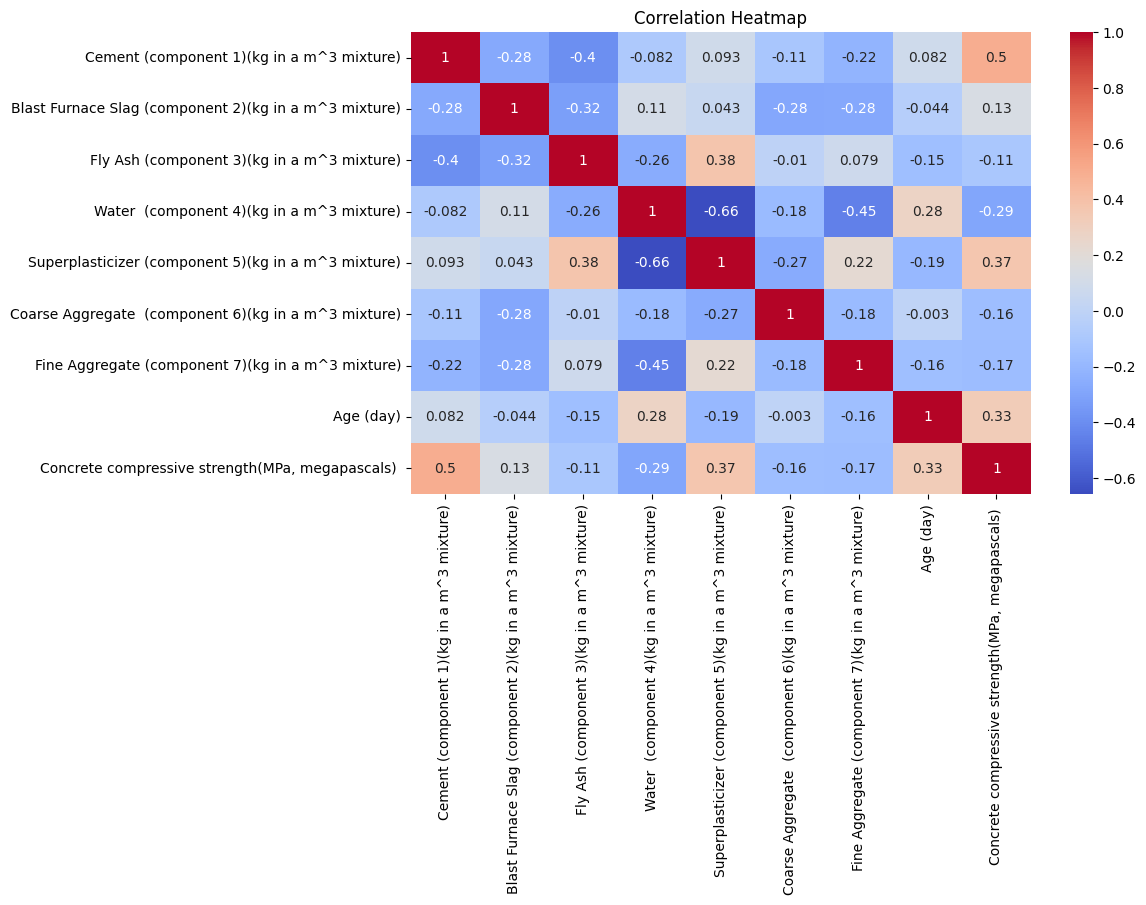

In [4]:
plt.figure(figsize=(10, 6))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

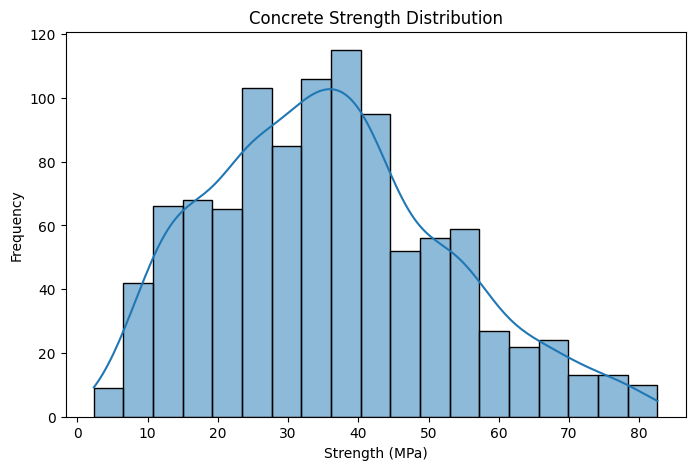

In [5]:
#Concrete strength distribution
plt.figure(figsize=(8, 5))
sns.histplot(df.iloc[:, -1], kde=True)
plt.title("Concrete Strength Distribution")
plt.xlabel("Strength (MPa)")
plt.ylabel("Frequency")
plt.show()

In [6]:
X = df.iloc[:, :-1]
y = df.iloc[:, -1]
print("Input Features:", X.shape)
print("Output:", y.shape)
print("\nInput Feature Names:")
print(X.columns.tolist())

Input Features: (1030, 8)
Output: (1030,)

Input Feature Names:
['Cement (component 1)(kg in a m^3 mixture)', 'Blast Furnace Slag (component 2)(kg in a m^3 mixture)', 'Fly Ash (component 3)(kg in a m^3 mixture)', 'Water  (component 4)(kg in a m^3 mixture)', 'Superplasticizer (component 5)(kg in a m^3 mixture)', 'Coarse Aggregate  (component 6)(kg in a m^3 mixture)', 'Fine Aggregate (component 7)(kg in a m^3 mixture)', 'Age (day)']


In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Training Data:", X_train_scaled.shape)
print("Testing Data:", X_test_scaled.shape)

Training Data: (824, 8)
Testing Data: (206, 8)


In [ ]:
#Applying PCA

In [8]:
from sklearn.decomposition import PCA
pca_full = PCA()
pca_full.fit(X_train_scaled)
variance = pca_full.explained_variance_ratio_
print("Explained Variance Ratio:")
for i, value in enumerate(variance):
    print(f"PC{i+1}: {value*100:.2f}%")

Explained Variance Ratio:
PC1: 28.02%
PC2: 17.91%
PC3: 16.83%
PC4: 12.80%
PC5: 11.81%
PC6: 9.94%
PC7: 2.30%
PC8: 0.39%


In [ ]:
#Variance

In [9]:
cumulative_variance = np.cumsum(variance)
variance_table = pd.DataFrame({
    "Principal Component": [
        f"PC{i+1}" for i in range(len(variance))
    ],
    "Explained Variance (%)": variance * 100,
    "Cumulative Variance (%)": cumulative_variance * 100
})

display(variance_table.round(2))

,Principal Component,Explained Variance (%),Cumulative Variance (%)
0,PC1,28.02,28.02
1,PC2,17.91,45.93
2,PC3,16.83,62.76
3,PC4,12.80,75.56
4,PC5,11.81,87.37
5,PC6,9.94,97.31
6,PC7,2.30,99.61
7,PC8,0.39,100.00


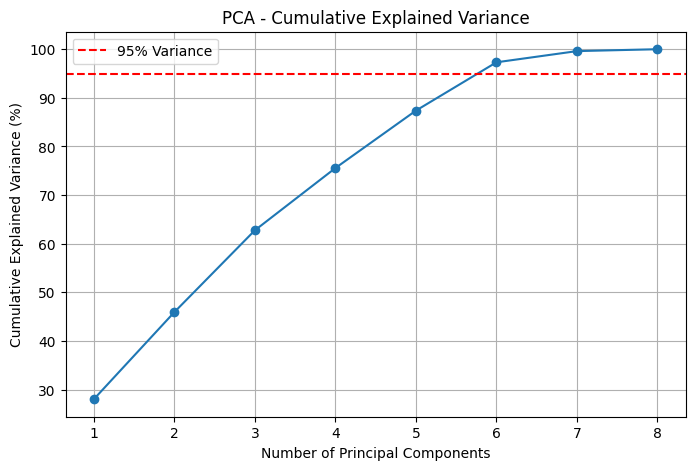

In [10]:
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, 9),
    cumulative_variance * 100,
    marker="o"
)
plt.axhline(
    y=95,
    color="red",
    linestyle="--",
    label="95% Variance"
)
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("PCA - Cumulative Explained Variance")
plt.xticks(range(1, 9))
plt.legend()
plt.grid()
plt.show()

In [11]:
n = np.argmax(cumulative_variance >= 0.95) + 1
print("Original Features:", X.shape[1])
print("Selected Components:", n)
print(
    "Variance Retained:",
    round(cumulative_variance[n-1] * 100, 2),
    "%")
print(
    "Dimensions Reduced:",
    X.shape[1] - n)

Original Features: 8
Selected Components: 6
Variance Retained: 97.31 %
Dimensions Reduced: 2


In [12]:
pca = PCA(n_components=n)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)
print("Before PCA:", X_train_scaled.shape)
print("After PCA:", X_train_pca.shape)

Before PCA: (824, 8)
After PCA: (824, 6)


In [ ]:
#PCA coeffients

In [13]:
pca_coefficients = pd.DataFrame(
    pca.components_,
    columns=X.columns,
    index=[f"PC{i+1}" for i in range(n)])
print("PCA Component Coefficients:")
display(pca_coefficients.round(3))

PCA Component Coefficients:


,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day)
PC1,0.121,0.144,-0.395,0.545,-0.514,0.061,-0.400,0.290
PC2,-0.276,0.709,-0.117,0.115,0.188,-0.587,0.027,-0.117
PC3,0.760,-0.041,-0.446,-0.217,0.284,-0.288,0.025,0.103
PC4,-0.092,-0.375,0.114,0.273,-0.136,-0.491,0.534,0.467
PC5,-0.118,0.041,-0.553,-0.121,-0.372,0.177,0.590,-0.382
PC6,-0.234,0.298,-0.203,-0.368,0.148,0.346,0.124,0.723


In [14]:
print("PCA MATHEMATICAL EQUATIONS\n")
for i, weights in enumerate(pca.components_):
    equation = f"PC{i+1} = "
    terms = []
    for weight, feature in zip(weights, X.columns):
        terms.append(f"({weight:.3f} × {feature})")
    equation += " + ".join(terms)
    print(equation)
    print()

PCA MATHEMATICAL EQUATIONS

PC1 = (0.121 × Cement (component 1)(kg in a m^3 mixture)) + (0.144 × Blast Furnace Slag (component 2)(kg in a m^3 mixture)) + (-0.395 × Fly Ash (component 3)(kg in a m^3 mixture)) + (0.545 × Water  (component 4)(kg in a m^3 mixture)) + (-0.514 × Superplasticizer (component 5)(kg in a m^3 mixture)) + (0.061 × Coarse Aggregate  (component 6)(kg in a m^3 mixture)) + (-0.400 × Fine Aggregate (component 7)(kg in a m^3 mixture)) + (0.290 × Age (day))

PC2 = (-0.276 × Cement (component 1)(kg in a m^3 mixture)) + (0.709 × Blast Furnace Slag (component 2)(kg in a m^3 mixture)) + (-0.117 × Fly Ash (component 3)(kg in a m^3 mixture)) + (0.115 × Water  (component 4)(kg in a m^3 mixture)) + (0.188 × Superplasticizer (component 5)(kg in a m^3 mixture)) + (-0.587 × Coarse Aggregate  (component 6)(kg in a m^3 mixture)) + (0.027 × Fine Aggregate (component 7)(kg in a m^3 mixture)) + (-0.117 × Age (day))

PC3 = (0.760 × Cement (component 1)(kg in a m^3 mixture)) + (-0.041 × B

In [15]:
pca_df = pd.DataFrame(
    X_train_pca,
    columns=[f"PC{i+1}" for i in range(n)]
)

print("PCA Transformed Dataset:")

display(pca_df.head())

PCA Transformed Dataset:


,PC1,PC2,PC3,PC4,PC5,PC6
0,-1.175582,1.221243,-0.836481,-0.738225,-1.206013,0.293232
1,-0.800972,0.276400,1.139602,0.816527,-1.381891,-1.513256
2,-1.610579,-1.227429,-0.455766,-0.707654,-0.239825,-0.113584
3,-0.414697,1.429941,0.066476,1.143886,-0.186180,-0.826347
4,-1.858740,-0.789730,-1.284761,-0.876339,0.017924,0.444122


In [ ]:
#REGRESSION WITHOUT PCA

In [16]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

model1 = LinearRegression()

model1.fit(X_train_scaled, y_train)

pred1 = model1.predict(X_test_scaled)

mae1 = mean_absolute_error(y_test, pred1)
mse1 = mean_squared_error(y_test, pred1)
rmse1 = np.sqrt(mse1)
r2_1 = r2_score(y_test, pred1)

print("REGRESSION WITHOUT PCA")

print("MAE:", mae1)
print("MSE:", mse1)
print("RMSE:", rmse1)
print("R2 Score:", r2_1)

REGRESSION WITHOUT PCA
MAE: 7.745392872421345
MSE: 95.97548435337703
RMSE: 9.796707832398445
R2 Score: 0.6275416055429022


In [ ]:
#REGRESSION WITH PCA

In [17]:
model2 = LinearRegression()
model2.fit(X_train_pca, y_train)
pred2 = model2.predict(X_test_pca)
mae2 = mean_absolute_error(y_test, pred2)
mse2 = mean_squared_error(y_test, pred2)
rmse2 = np.sqrt(mse2)
r2_2 = r2_score(y_test, pred2)
print("REGRESSION WITH PCA")
print("MAE:", mae2)
print("MSE:", mse2)
print("RMSE:", rmse2)
print("R2 Score:", r2_2)

REGRESSION WITH PCA
MAE: 8.487613218614968
MSE: 111.33431082145741
RMSE: 10.551507514163907
R2 Score: 0.5679375943145377


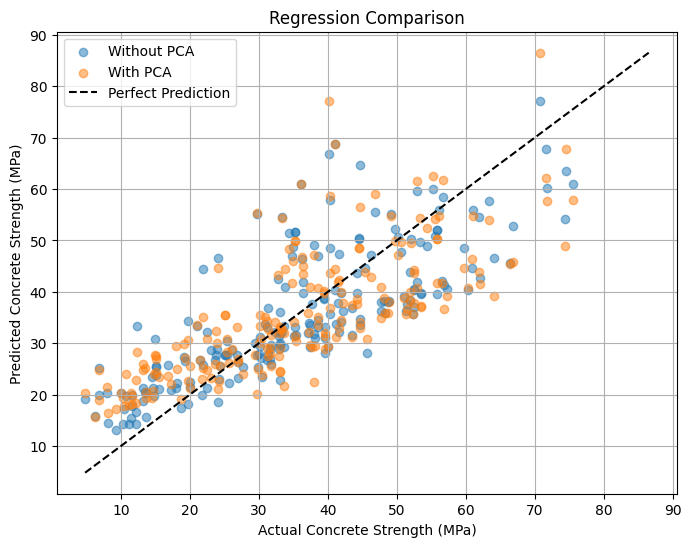

In [21]:
plt.figure(figsize=(8, 6))
plt.scatter(
    y_test, pred1,
    label="Without PCA",
    alpha=0.5)
plt.scatter(
    y_test, pred2,
    label="With PCA",
    alpha=0.5)
minimum = min(y_test.min(), pred1.min(), pred2.min())
maximum = max(y_test.max(), pred1.max(), pred2.max())
plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    "k--",
    label="Perfect Prediction")
plt.xlabel("Actual Concrete Strength (MPa)")
plt.ylabel("Predicted Concrete Strength (MPa)")
plt.title("Regression Comparison")
plt.legend()
plt.grid()
plt.show()

In [18]:
variance_without_pca = 100.0
variance_with_pca = (
    np.sum(pca.explained_variance_ratio_) * 100
)
performance_matrix = pd.DataFrame({
    "Metric": [
        "Input features",
        "Variance retained (%)",
        "MAE",
        "MSE",
        "RMSE",
        "R2 Score"
    ],

    "Without PCA": [
        X_train_scaled.shape[1],
        variance_without_pca,
        mae1,
        mse1,
        rmse1,
        r2_1
    ],

    "With PCA": [
        X_train_pca.shape[1],
        variance_with_pca,
        mae2,
        mse2,
        rmse2,
        r2_2
    ]
})

performance_matrix = performance_matrix.set_index("Metric")

print("MODEL PERFORMANCE MATRIX")

display(performance_matrix.round(4))

MODEL PERFORMANCE MATRIX


,Without PCA,With PCA
Metric,,
Input features,8.0000,6.0000
Variance retained (%),100.0000,97.3099
MAE,7.7454,8.4876
MSE,95.9755,111.3343
RMSE,9.7967,10.5515
R2 Score,0.6275,0.5679


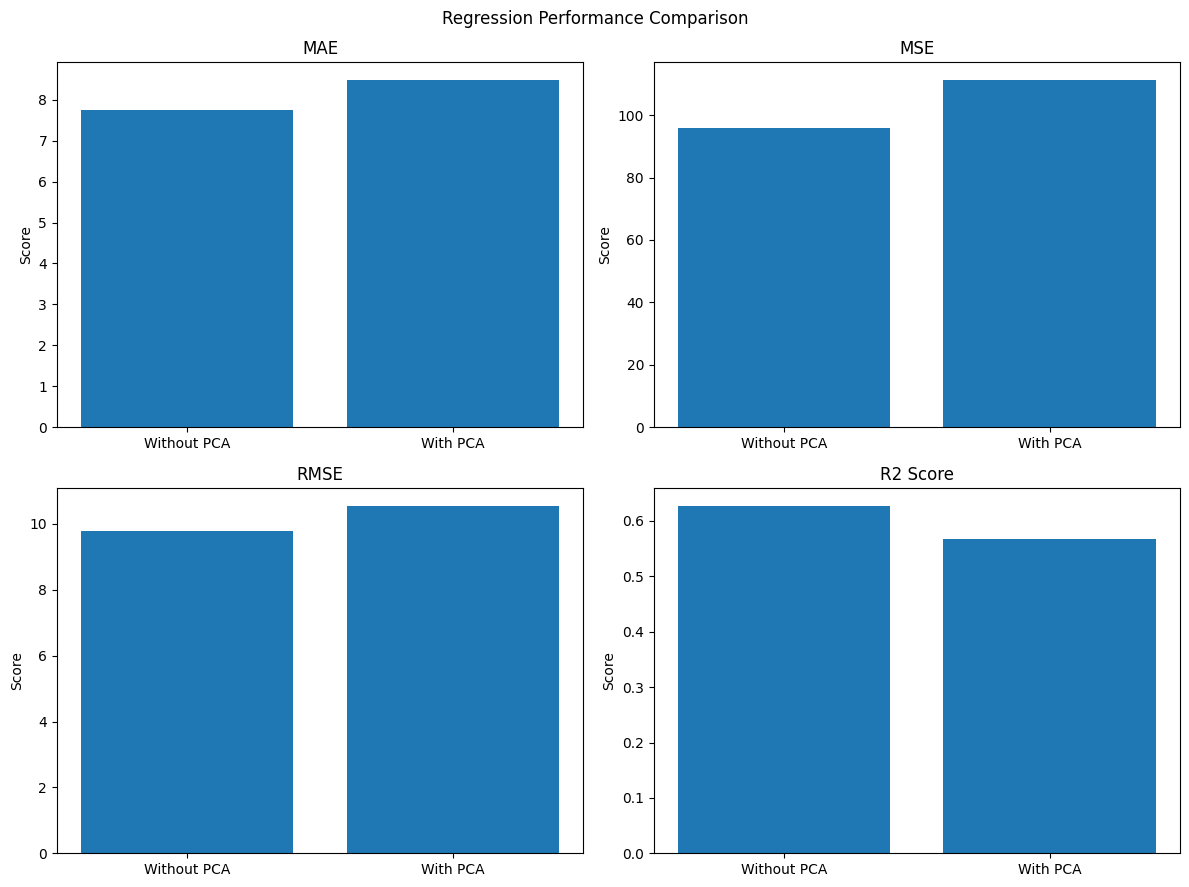

In [19]:
metrics = ["MAE", "MSE", "RMSE", "R2 Score"]
without_pca = [mae1, mse1, rmse1, r2_1]
with_pca = [mae2, mse2, rmse2, r2_2]
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for i, ax in enumerate(axes.flat):
    ax.bar(
        ["Without PCA", "With PCA"],
        [without_pca[i], with_pca[i]])
    ax.set_title(metrics[i])
    ax.set_ylabel("Score")
plt.suptitle("Regression Performance Comparison")
plt.tight_layout()
plt.show()

In [ ]:
#Results

In [23]:
print("Results")
print("Original Features:", X.shape[1])
print("Selected Principal Components:", n)
print(
    "Variance Retained:",
    round(variance_with_pca, 2), "%")
print("\nRegression Comparison:")
print("Without PCA RMSE:", round(rmse1, 4))
print("With PCA RMSE:", round(rmse2, 4))
print("Without PCA R2:", round(r2_1, 4))
print("With PCA R2:", round(r2_2, 4))
if rmse2 < rmse1:
    print("\nPCA improved regression accuracy.")
elif rmse2 > rmse1:
    print("\nPCA reduced regression accuracy.")
else:
    print("\nBoth models have equal RMSE.")
print(
    "Dimensionality Reduction:",
    round((1 - n / X.shape[1]) * 100, 2),
    "%")

Results
Original Features: 8
Selected Principal Components: 6
Variance Retained: 97.31 %

Regression Comparison:
Without PCA RMSE: 9.7967
With PCA RMSE: 10.5515
Without PCA R2: 0.6275
With PCA R2: 0.5679

PCA reduced regression accuracy.
Dimensionality Reduction: 25.0 %
